# 04 · Specialty evolution

**Question:** how did chemistry's sub-fields emerge and grow?

**Method** (`chemkg.occupations`)
- Co-occurrence graph: nodes are the 46 occupation labels; an edge joins two labels held by the same person, weighted by count and Jaccard.
- First appearance: the earliest holder's birth year and the birth year by which **3** holders exist (robust to one retro-tagged figure).
- Growth: people per birth decade holding each domain.

**Assumption:** labels are applied retrospectively by Wikidata editors. 'Emergence' means adoption of the label for people born then, not the founding of the field.

In [1]:
import json, warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from chemkg.data import load, analysable
from chemkg import countries
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
ds = load()
P, A = ds.people, analysable(ds.people)
NAMES = countries.load_iso3().set_index("iso3").name.to_dict()
print(f"{len(P):,} people, {len(A):,} analysable; enrichment loaded: {ds.enriched}")

11,903 people, 11,860 analysable; enrichment loaded: True


In [2]:
from chemkg import occupations
nodes, edges = occupations.cooccurrence(ds.person_occupation, set(A.qid))
edges.head(15)

,a,b,n,jaccard
0,biochemist,chemist,557,0.054379
1,chemist,pharmacologist,112,0.012613
2,chemical engineer,chemist,87,0.009892
3,chemist,crystallographer,68,0.008030
4,biochemist,pharmacologist,66,0.021442
5,chemist,physical chemist,57,0.006751
6,biochemist,crystallographer,27,0.010147
7,chemist,geochemist,27,0.003194
8,chemist,organic chemist,21,0.002515
9,chemist,theoretical chemist,17,0.002039


In [3]:
first = occupations.first_appearance(ds.person_occupation, A)
first[first.n >= 5]

,occupation,domain,first_year,first_person,first_qid,year_k3,median_year,n
0,pharmacologist,Life & medicinal chemistry,-201,Crateuas,Q743993,50.0,1922.0,593
1,chemist,General chemistry,-1201,Tapputi,Q4355213,810.0,1915.0,7709
2,crystallographer,Physical & theoretical,1638,Nicolas Steno,Q151722,1685.0,1916.0,203
3,biochemist,Life & medicinal chemistry,1784,Georg Karl Ludwig Sigwart,Q1503892,1795.0,1935.0,2201
4,toxicologist,Life & medicinal chemistry,1787,Mathieu Orfila,Q704342,1812.0,1928.5,76
5,agricultural chemist,Applied & industrial,1817,Wilhelm Knop,Q68077,1830.0,1843.0,13
6,organic chemist,Synthesis & materials,1767,Nicolas Théodore de Saussure,Q116058,1838.0,1929.0,38
7,chemical engineer,Applied & industrial,1845,Carl Daniel Ekman,Q5040021,1848.0,1940.0,441
8,physical chemist,Physical & theoretical,1748,Charles Blagden,Q1063743,1857.0,1930.0,151
9,chemical technologist,Applied & industrial,1814,Friedrich Ludwig Knapp,Q74297,1870.0,1934.0,18


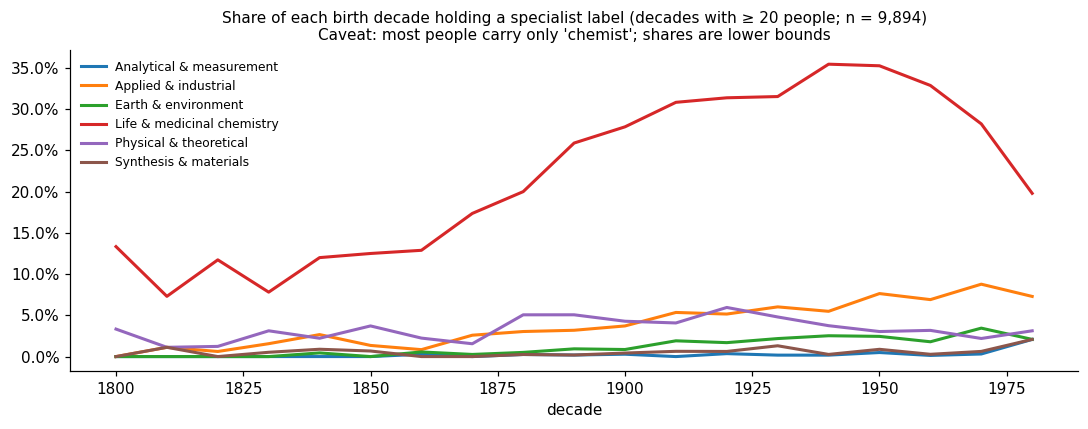

In [4]:
growth = occupations.growth_by_decade(ds.person_occupation, A)
tot = A.dropna(subset=["birth_year"]).assign(d=lambda d: (d.birth_year // 10 * 10).astype(int)).groupby("d").size()
share = growth.div(tot.reindex(growth.index), axis=0).loc[1800:1990]
share = share[tot.reindex(share.index) >= 20]
ax = share.drop(columns=["General chemistry"]).plot(figsize=(10, 4), lw=2)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title(f"Share of each birth decade holding a specialist label (decades with ≥ 20 people; n = {int(tot.loc[1800:1999].sum()):,})\nCaveat: most people carry only 'chemist'; shares are lower bounds", fontsize=10)
ax.legend(frameon=False, fontsize=8); plt.tight_layout()

### Reading the result
- Life & medicinal chemistry (biochemistry, pharmacology, toxicology) grows from about a seventh of cohorts born in the mid-19th century to about a third of those born in the mid-20th. It is the main structural change in the profession.
- `chemist + biochemist` is the dominant pair, and pharmacology bridges biochemistry and toxicology.
- Apart from the generic label, the best-connected specialties are biochemist, physical chemist, pharmacologist and chemical engineer.